In [143]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
import ast

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x)if pd.notnull(x) else x)

In [145]:
#"What are the top 10 skills required for Data Analyst jobs posted in January 2023 in Kenya?"

df_kenya = df[df['job_country'] == 'Kenya']

In [146]:
df_jan_2023 = df_kenya[
    (df_kenya['job_posted_date'].dt.year == 2023) &
    (df_kenya['job_posted_date'].dt.month == 1)
]

In [147]:
df_da = df_jan_2023[df_jan_2023['job_title_short'] == 'Data Analyst']


In [ ]:
df_da = df_da.dropna(subset=['job_skills'])

df_da

In [ ]:
df_da = df_da.explode('job_skills')

df_da

In [ ]:
skill_counts = df_da['job_skills'].value_counts()
skill_counts

In [151]:
top_10_skills = skill_counts.sort_values(
    ascending=False
).head(10)

In [ ]:
top_10_skills

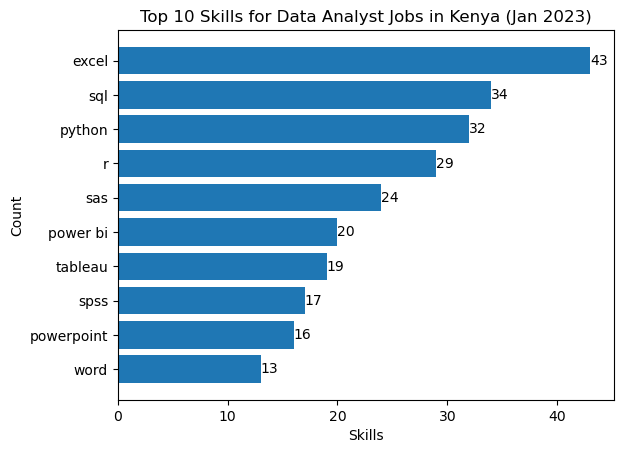

In [153]:
plt.barh(top_10_skills.index, top_10_skills.values)
plt.title('Top 10 Skills for Data Analyst Jobs in Kenya (Jan 2023)')
plt.xlabel('Skills')
plt.ylabel('Count')
plt.bar_label(
    bars,
)
plt.gca().invert_yaxis()
plt.show()

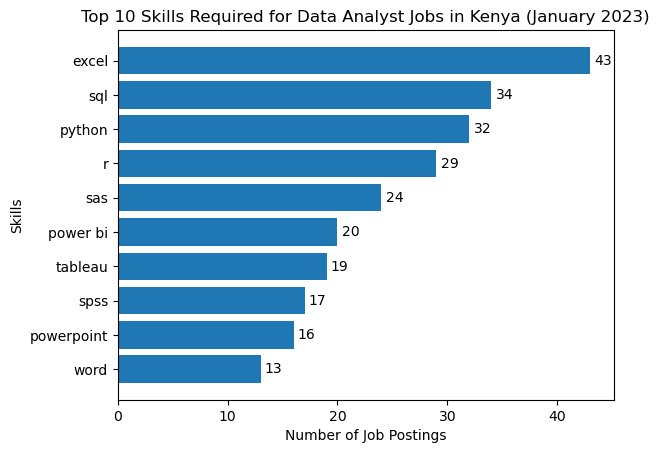

In [154]:
bars = plt.barh(
    top_10_skills.index,
    top_10_skills.values
)

plt.xlabel("Number of Job Postings")
plt.ylabel("Skills")

plt.title(
    "Top 10 Skills Required for Data Analyst Jobs in Kenya (January 2023)"
)

plt.bar_label(
    bars,
    padding=3
)

plt.gca().invert_yaxis()

plt.show()